# `fast_statistics_test.ipynb`

This file is meant to be temporary to set up functions to load simulation data & compute statistics.

In [6]:
import os
import pandas as pd
import numpy as np
import ast
import testis_model as tm

from saving_loading import find_scenarios, load_all_scenarios, load_clone_names
from testis_model.metrics import init_time, max_time, last_time, freq_at, size, avg_freq_change
from testis_model.metrics import run_likelihood

In [7]:
fish_data, clone_data = load_all_scenarios('n1000_r3_y6')

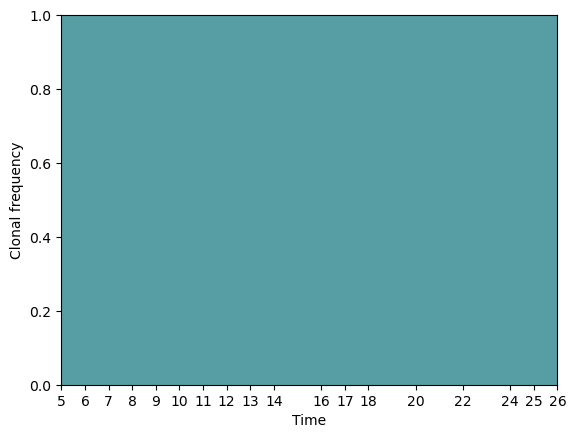

In [10]:
data = clone_data['n1000_r3_y6', 2, 9]
tm.visualize.plot(data)

In [11]:
data

,group,fish,clone,time,n_sperm,obs_result,hid_result,full_result,replicate,clone_freq
0,n1000_r3_y6,2,9,5.0,371,"(0, 371)","(0, 1000)","(0, 3835654)",1,0.0
1,n1000_r3_y6,2,9,6.0,371,"(0, 371)","(0, 1000)","(0, 3948987)",1,0.0
2,n1000_r3_y6,2,9,7.0,371,"(0, 371)","(0, 1000)","(0, 3885171)",1,0.0
3,n1000_r3_y6,2,9,8.0,371,"(0, 371)","(0, 1000)","(0, 3954465)",1,0.0
4,n1000_r3_y6,2,9,9.0,371,"(0, 371)","(0, 1000)","(0, 3936940)",1,0.0
5,n1000_r3_y6,2,9,10.0,371,"(0, 371)","(0, 1000)","(0, 3867308)",1,0.0
6,n1000_r3_y6,2,9,11.0,371,"(0, 371)","(0, 1000)","(0, 3955166)",1,0.0
7,n1000_r3_y6,2,9,12.0,371,"(0, 371)","(0, 1000)","(0, 3811880)",1,0.0
8,n1000_r3_y6,2,9,13.0,371,"(0, 371)","(0, 1000)","(0, 3964911)",1,0.0
9,n1000_r3_y6,2,9,14.0,371,"(0, 371)","(0, 1000)","(0, 3957955)",1,0.0


In [9]:
last_time(data)

26.0

In [12]:
max_time(data)

26.0

In [7]:
all_series = []
for (scenario, fish, clone), data in clone_data.items():
    # print(scenario, fish, clone)
    series = dict()
    series['scenario'] = scenario
    series['fish'] = fish
    series['clone'] = clone
    series['init_time'] = init_time(data)
    series['last_time'] = last_time(data)
    series['max_time'] = max_time(data)
    series['init_freq'] = freq_at(data, series['init_time'])
    series['max_freq'] = freq_at(data, series['max_time'])
    series['size'] = size(data)
    series['avg_freq_change'] = avg_freq_change(data)
    all_series.append(series)

df = pd.DataFrame(all_series)
df.head()

,scenario,fish,clone,init_time,last_time,max_time,init_freq,max_freq,size,avg_freq_change
0,n500_r0_y4,0,0,1,18.0,18.0,0.320755,0.345013,0.345013,-0.001427
1,n500_r0_y4,0,1,1,18.0,18.0,0.169811,0.169811,0.172207,0.000000
2,n500_r0_y4,0,2,1,18.0,18.0,0.150943,0.134771,0.135669,0.000951
3,n500_r0_y4,0,3,1,18.0,18.0,0.080863,0.078167,0.072627,0.000159
4,n500_r0_y4,0,4,1,18.0,18.0,0.078167,0.078167,0.082959,0.000000


## Debug

In [ ]:
import importlib
import metrics
importlib.reload(metrics)
from metrics import last_time

In [ ]:
data = clone_data['real', 1, 3]
# avg_freq_change(data)
last_time(data)

In [ ]:
data

In [ ]:
data = tm.data_processing.normalize_sperm_counts(data.copy(), 500)
it = init_time(data)
init_size = freq_at(data, it)
init_sperm_freq = np.array([init_size, 1 - init_size])

a = run_binom_likelihood(data)

In [ ]:
a